# 07 · Other land-change tools at 100 m

**Question:** on the platform's 100 m grid, do established land-change tools forecast better than the deployed method, and is the order of the tools the same as at 250 m?

The test of the 250 m comparison (`../../grid_250m/2_improvement_and_benchmark/BENCHMARK_DETAILS.md`): learn from Esri 2023 → 2024, forecast 2025 from the 2024 map, score against Esri 2025 inside Guinea; the test window of notebook 04. Every tool gets the files of `scripts/tools_export100.py` and is scored with notebook 04's scorer (`deployed100.score`). Runs: `scripts/run07.py`; code: `scripts/tools100.py`.

Two comparisons, as at 250 m:

* **as it runs:** each tool's own forecast, with the amount of change it is given (the observed 2025 class totals, or the platform's projection) or, for MOLUSCE, the amount it computes itself;
* **same amount:** each tool's suitability maps place the observed number of each 2024 → 2025 transition with `main`'s allocator, as the backend's "observed" runs; only *where* change goes differs.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import tools100 as T
import decisions100 as M
D, C, G = T.D, T.C, T.G
H = C.H

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30, "display.width", 200)
OUTS = Path.cwd().parent / "outputs"
S = T.scores()
ours = pd.concat([D.scores().query("variant == 'as it runs' and method == 'backend'"), M.scores()])
ours = ours[ours.phase == "test"]
print(f"{len(S)} tool scores; main's own figure_of_merit agrees with ours within {(S['FoM'] - S['platform FoM']).abs().max():.3f} points")

20 tool scores; main's own figure_of_merit agrees with ours within 0.005 points


## 1 · How each tool was run, and the check of the code versions

MOLUSCE froze in QGIS at 100 m (two causes, both found: 17 cells of slope and aspect without a value in the export, which make MOLUSCE mask the whole layer, and its memory use), so PLUS and FLUS were run in their own programs and MOLUSCE and CLUE-S from code. Each code version was first checked against the tool's own program at 250 m, where both exist.

| Tool | At 100 m | How | Check at 250 m |
|---|---|---|---|
| PLUS (Liang et al. 2021) | its program (GUI) | LEAS random forest, CARS cellular automata; settings of the 250 m run | not needed |
| MOLUSCE 5.1 (NextGIS) | code | its own algorithms outside QGIS (`scripts/molusce_run.py`), with the 250 m GUI settings; factor maps held in float32 and once instead of twice, to fit in memory | below |
| CLUE-S (Verburg et al. 2002; Dyna-CLUE 2.7) | code | Python port of the authors' allocation (`scripts/clue_s.py`) | same map as the authors' program on 100.00 % of pixels, Figure of Merit 14.78 % against 14.76 % for lulcc (`BENCHMARK_DETAILS.md`, section 5) |
| FLUS (Liu et al. 2017) | its program (GeoSOS-FLUS 2.3, GUI) | neural network and cellular automaton, settings of the 250 m runs; the copy of its network (`scripts/flus_ann.py`) adds three seeds of its suitability maps | not needed; its network copy: 19.79 % against FLUS's 20.04 % with the same amount (250 m notebook 09) |

**MOLUSCE: code against its program.** The code was run four times (float64 and float32 with seed 0; float32 with seeds 1 and 2); MOLUSCE draws its 50,000 training samples at random, as its program does in every run (`scripts/tools_check250.py`).

In [2]:
check_molusce = pd.read_csv(OUTS / "07_check250_molusce.csv", index_col=0)
check_molusce.round(2)

,method,changes forecast,FoM as it runs %,FoM same amount %,"same class as the GUI map, % of pixels"
"MOLUSCE LR, GUI",LR,65794,3.64,19.81,100.00
"MOLUSCE LR, code, float64, seed 0",LR,80602,4.16,19.06,98.52
"MOLUSCE LR, code, float32, seed 0",LR,82036,4.12,19.37,98.54
"MOLUSCE LR, code, float32, seed 1",LR,76450,4.09,19.78,98.60
"MOLUSCE LR, code, float32, seed 2",LR,86387,4.19,19.74,98.51
"MOLUSCE ANN, GUI",ANN,3043,0.07,10.34,100.00
"MOLUSCE ANN, code, float32, seed 0",ANN,217,0.02,10.26,99.92


**Reading:**

* **Given the same amount of change, the code places change like MOLUSCE's program:** 19.06–19.78 % over four runs, against 19.81 % for the program's run, at the top of the code's run-to-run range; the maps give the same class on 98.5–98.6 % of Guinea's pixels. The ANN: 10.26 % against 10.34 %.
* **As it runs, the code forecasts a little more change** (76,000–86,000 pixels against 66,000) and scores 4.1–4.2 % against 3.6 %. Both are far below every other tool, so the order of the tools does not change. The number of changes depends on what the model learns from its 50,000 random samples; the program's run is one draw.
* **float32 and float64 differ like two seeds** (19.37 and 19.06 % with the same seed): MOLUSCE stops its regression after 100 iterations, before it has converged, so small rounding differences change the fit.
* So MOLUSCE's code stands in for its program at 100 m, labelled "code".

## 2 · Scores at 100 m

Figure of Merit (%), test window: the mean over the runs of each method, with the seed spread (highest minus lowest score over three seeds) in its own columns. A difference between two methods counts only if it is larger than the larger of their spreads (Bouthillier et al. 2021). Our methods and MOLUSCE LR: three seeds; FLUS: one run of its program, and three seeds of its network copy for the same amount; CLUE-S gives the same map every run; PLUS and MOLUSCE ANN: one run. Random: the same forecast changes placed at random among the cells of each start class.

In [3]:
COLS = ["as it runs, observed amount", "as it runs, projected amount", "same amount"]

def ours_runs(method):
    o = ours[ours.method == method]
    return dict(zip(COLS, (o[o.demand == "observed"], o[o.demand == "projected"], o[o.demand == "observed"])))

def tool_runs(*keys):
    return {col: S.loc[[k for k in ks if k in S.index]] for col, ks in zip(COLS, keys)}

lr = ["molusce_lr", "molusce_lr_s1", "molusce_lr_s2"]
methods = {
    "Our best: blend (notebook 05)": ("code", ours_runs("blend")),
    "Methodology document": ("code", ours_runs("document")),
    "Backend (main)": ("code", ours_runs("backend")),
    "FLUS 2.3": ("GUI", tool_runs(["flus_observed"], ["flus_projected"], ["flus_same"])),
    "FLUS, network copy": ("code", tool_runs([], [], ["flus_same_s42", "flus_same_s1", "flus_same_s2"])),
    "MOLUSCE LR": ("code", tool_runs(lr, lr, [k + "_same" for k in lr])),
    "CLUE-S": ("code", tool_runs(["clue_s_observed"], ["clue_s_projected"], ["clue_s_same"])),
    "PLUS": ("GUI", tool_runs(["plus_observed"], ["plus_projected"], ["plus_same"])),
    "MOLUSCE ANN": ("code", tool_runs(["molusce_ann"], ["molusce_ann"], ["molusce_ann_same"])),
}
spread = lambda r, cols: max([r[c]["FoM"].max() - r[c]["FoM"].min() for c in cols if len(r[c]) > 1], default=np.nan)
mean = lambda v, col="FoM": v[col].mean() if len(v) else np.nan
tab = pd.DataFrame({name: {"run": run, "runs": max(len(v) for v in r.values()),
                           **{col: mean(r[col]) for col in COLS},
                           "seed spread, as it runs": spread(r, COLS[:2]), "seed spread, same amount": spread(r, COLS[2:]),
                           "random, same amount": mean(r[COLS[2]], "random FoM")}
                    for name, (run, r) in methods.items()}).T
C.save("07_scores.csv", tab)
tab.round(2)

,run,runs,"as it runs, observed amount","as it runs, projected amount",same amount,"seed spread, as it runs","seed spread, same amount","random, same amount"
Our best: blend (notebook 05),code,3,20.013394,15.262204,20.013394,0.191,0.179256,8.575063
Methodology document,code,3,18.603957,14.083636,18.603957,0.196415,0.196415,8.575349
Backend (main),code,3,17.306687,12.728639,17.306687,0.297394,0.212899,8.570033
FLUS 2.3,GUI,1,17.906404,16.522158,18.72493,NaN,NaN,8.58708
"FLUS, network copy",code,3,NaN,NaN,18.530354,NaN,0.191623,8.579561
MOLUSCE LR,code,3,4.354849,4.354849,19.554864,1.195091,0.386647,8.580286
CLUE-S,code,1,13.810493,5.312062,17.262555,NaN,NaN,8.500328
PLUS,GUI,1,13.163887,4.746727,10.831513,NaN,NaN,8.564859
MOLUSCE ANN,code,1,0.382768,0.382768,7.263098,NaN,NaN,7.952338


MOLUSCE is given no amount: it repeats the 2023 → 2024 transitions, capped by what its model predicts, so its "as it runs" score is the same in both amount columns, as at 250 m (notebook 10).

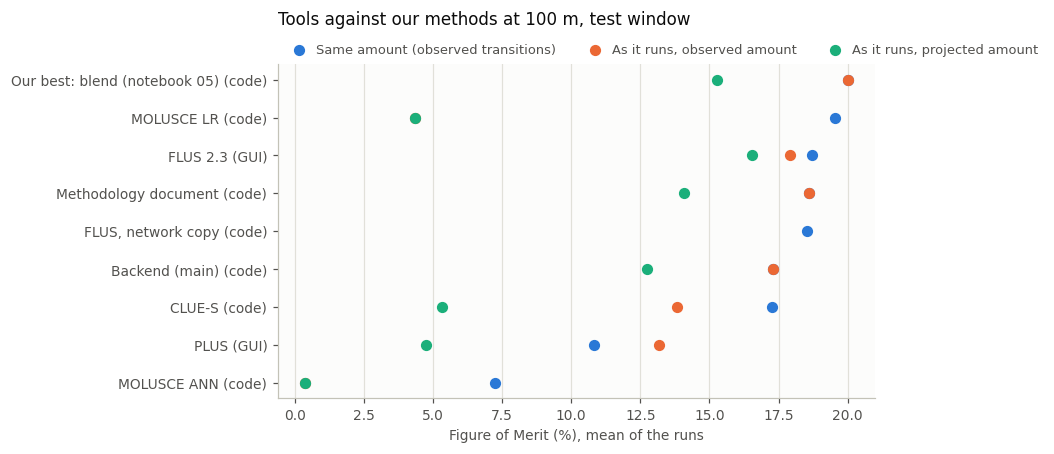

In [4]:
order = tab["same amount"].astype(float).sort_values().index
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for col, colour, label in (("same amount", H.SERIES[0], "Same amount (observed transitions)"),
                           ("as it runs, observed amount", H.SERIES[1], "As it runs, observed amount"),
                           ("as it runs, projected amount", H.SERIES[2], "As it runs, projected amount")):
    ax.scatter(tab.loc[order, col].astype(float), y, s=40, color=colour, zorder=3, label=label)
ax.set_yticks(y, [f"{n} ({tab.loc[n, 'run']})" for n in order])
ax.set_xlabel("Figure of Merit (%), mean of the runs", color=H.INK_2)
H.style_axes(ax)
ax.set_title("Tools against our methods at 100 m, test window", loc="left", color=H.INK, fontsize=11, pad=26)
ax.legend(frameon=False, fontsize=8.5, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, labelcolor=H.INK_2,
          handletextpad=0.3, borderaxespad=0.2)
plt.tight_layout(); plt.show()

**Reading:**

* **With the same amount of change, our best (the blend) places change best:** 20.01 % (seed spread 0.18), above MOLUSCE LR 19.55 % (0.39), FLUS 18.72 % (one run; its network copy 18.53 %, spread 0.19), the document's method 18.60 %, the backend 17.31 % and CLUE-S 17.26 %. The blend's lead over MOLUSCE LR (0.46) is larger than either spread, so it counts. PLUS (10.83 %) and MOLUSCE ANN (7.26 %, below random) are far behind.
* **As each runs with the observed amount, our best leads too:** 20.01 %, then the document's method 18.60 %, FLUS 17.91 %, the backend 17.31 %, CLUE-S 13.81 %, PLUS 13.16 %, and MOLUSCE under 5 %, which forecasts almost no change in one year (its simulator changes a pixel only where the most likely class differs from the current one). FLUS is 0.6 above the backend, more than the backend's spread (0.30).
* **With the platform's projected amount, FLUS's program scores highest:** 16.52 % against 15.26 % for the blend, 14.08 % for the document's method and 12.73 % for the backend. CLUE-S (5.31 %; it stopped at its limit of 20,000 iterations, 10.8 % off one class total) and PLUS (4.75 %) are far behind. Why FLUS leads is in the next table.
* For our methods "same amount" and "as it runs, observed amount" are the same forecast, so their dots coincide; MOLUSCE's two "as it runs" columns are both its own amount.
* **Over all of Guinea, with the same amount, our best has the most hits:** 1,045,566, which is 118,000 more than the backend and 45,500 more than MOLUSCE LR; MOLUSCE LR has the fewest false alarms (2.00 million, against 2.08 million for the blend and 2.20 million for the backend).

**How much each method changes.** The Figure of Merit rewards a forecast that changes more cells when much of the map changes (Pontius et al. 2008), so the forecasts "as they run" are also compared by how many cells they change and by their score divided by random placement of the same changes (as at 250 m, notebook 10). Observed: 3.17 million cells changed.

In [5]:
amount = pd.DataFrame({name: {
    **{f"cells changed, {c.split(', ')[1]}": mean(r[c], "predicted change (cells)") / 1e6 for c in COLS[:2]},
    **{f"× random, {c.split(', ')[1]}": mean(r[c].assign(x=r[c]["FoM"] / r[c]["random FoM"]), "x") for c in COLS[:2]}}
    for name, (run, r) in methods.items() if name != "FLUS, network copy"}).T
C.save("07_amount_and_random.csv", amount)
amount.round(2)

,"cells changed, observed amount","cells changed, projected amount","× random, observed amount","× random, projected amount"
Our best: blend (notebook 05),3.17,2.32,2.33,2.51
Methodology document,3.16,2.32,2.17,2.31
Backend (main),3.17,2.32,2.02,2.10
FLUS 2.3,5.66,5.06,1.79,1.97
MOLUSCE LR,0.53,0.53,2.69,2.69
CLUE-S,1.53,0.50,2.04,2.04
PLUS,3.37,0.49,1.62,1.83
MOLUSCE ANN,0.04,0.04,1.59,1.59


**Reading:**

* **FLUS changes far more cells than happened:** 5.7 million with the observed class totals and 5.1 million with the projected ones, against 3.2 million observed. Its cellular automaton only has to meet the class totals, and on the way it converts cells in both directions; in its observed run 1.2 million rangeland cells became trees in the last of its 17 iterations alone (`CA_simulation.txt`). Our methods change what they are given per transition: 3.2 million cells (observed) and 2.3 million (projected).
* **Against random placement of the same changes, our best is ahead of FLUS** with both amounts: 2.3 and 2.5 times random, against 1.8 and 2.0 for FLUS. So FLUS's lead with the projected amount comes from changing more than twice as many cells in a year when Esri's map changes a lot, not from placing change better; given the same changes, it is 1.3 points behind (table above).
* MOLUSCE LR is 2.7 times random, but on 0.5 million changed cells.

**Given FLUS's own changes.** The direct test: our methods' maps placed with exactly the transitions FLUS's two forecasts made (5.66 and 5.05 million cells), with `main`'s allocator (`scripts/run07_flus_amount.py`). The blend with its three seeds; the document's method and the backend with seed 42.

In [6]:
import json
fa = []
for f in sorted((T.CODE / "flus_amount").glob("*/score.json")):
    kind, tag = f.parent.name.split("_", 1)
    method = "blend" if "_blend_" in tag else "document" if "_document_" in tag else "backend"
    fa.append({"FLUS's amount": kind, "method": method, **json.loads(f.read_text())})
fa = pd.DataFrame(fa)
flus_own = {"observed": S.loc["flus_observed", "FoM"], "projected": S.loc["flus_projected", "FoM"]}
given = fa.groupby(["FLUS's amount", "method"])["FoM"].agg(["mean", "min", "max"]).unstack("method")["mean"]
given = given[["blend", "document", "backend"]].rename(columns={"blend": "our best: blend (3 seeds)", "document": "document's method",
                                                                 "backend": "backend (main)"})
given.insert(0, "FLUS 2.3", pd.Series(flus_own))
given.index = [f"FLUS's changes with the {k} class totals" for k in given.index]
C.save("07_given_flus_amount.csv", given)
given.round(2)

method,FLUS 2.3,our best: blend (3 seeds),document's method,backend (main)
FLUS's changes with the observed class totals,17.91,21.43,19.90,18.68
FLUS's changes with the projected class totals,16.52,18.96,17.56,16.37


**Reading:** **given the same changes as FLUS, the blend and the document's method place them better than FLUS does,** and the backend as well as FLUS (0.8 above with the observed changes, 0.15 below with the projected ones): the blend by 3.5 points with FLUS's observed run and 2.4 with its projected run, seed spread 0.1. FLUS's higher score "as it runs" with the projected amount is therefore its larger amount of change, not better placement. A better amount for our method was tested in notebook 05: recent-interval amounts win on one window and lose on another, because the direction of Esri's savanna–trees flicker turns from year to year, so the platform's trend is kept.

## 3 · The order at 250 m and at 100 m

The Figure of Merit depends on the cell size (more small changes at 100 m, notebook 01), so the two grids are compared by the order of the methods, not by their scores, each order among the methods scored on both grids. "Our best" is the improved method at 250 m (250 m notebook 11) and the blend of notebook 05 at 100 m. FLUS is its program on both grids. At 250 m: notebooks 09a and 10 (`../../outputs/summary/`); there the deployed method is the rebuild with three input errors corrected (250 m notebooks 05–06), not `main`'s backend, and the projected amount is a one-step Markov projection, not the platform's own.

In [7]:
SUMMARY = Path.cwd().parents[1] / "outputs" / "summary"
S250 = pd.read_csv(SUMMARY / "00_benchmark_detail.csv", index_col=0)["Figure of Merit %"]
P250 = pd.to_numeric(pd.read_csv(SUMMARY / "10_projected.csv", index_col=0).loc["Figure of Merit %"], errors="coerce")
names250 = {"Our best": "Improved method", "Backend (main)": "Deployed method", "PLUS": "PLUS", "CLUE-S": "CLUE-S",
            "MOLUSCE LR": "MOLUSCE LR", "MOLUSCE ANN": "MOLUSCE ANN", "FLUS 2.3": "FLUS"}
t100 = tab.rename(index={"Our best: blend (notebook 05)": "Our best"})
KINDS = ["same amount", "as it runs, observed amount", "as it runs, projected amount"]
both = pd.DataFrame({
    "same amount, 250 m": {k: S250.get(f"{v}, same amount of change", S250.get(f"{v}, as it runs")) for k, v in names250.items()},
    "as it runs, observed amount, 250 m": {k: S250.get(f"{v}, as it runs") for k, v in names250.items()},
    "as it runs, projected amount, 250 m": {k: float(P250.get(v, np.nan)) for k, v in names250.items()},
    **{f"{kind}, 100 m": t100.loc[list(names250), kind].astype(float) for kind in KINDS},
})[[f"{kind}, {g}" for kind in KINDS for g in ("250 m", "100 m")]]
ranks = {}
for kind in KINDS:                                  # ranked among the methods scored on both grids
    ok = both[f"{kind}, 250 m"].notna() & both[f"{kind}, 100 m"].notna()
    for g in ("250 m", "100 m"):
        ranks[f"{kind}, {g}"] = both.loc[ok, f"{kind}, {g}"].rank(ascending=False)
ranks = pd.DataFrame(ranks).reindex(both.index).astype("Int64")
C.save("07_order_250_100.csv", both.join(ranks, rsuffix=" (rank)"))
pd.concat({"Figure of Merit %": both.round(2), "rank": ranks}, axis=1)

Figure of Merit %                                                                                                                                                                   \
               same amount, 250 m same amount, 100 m as it runs, observed amount, 250 m as it runs, observed amount, 100 m as it runs, projected amount, 250 m as it runs, projected amount, 100 m   
Our best                    20.37              20.01                              20.37                              20.01                                13.1                               15.26   
Backend (main)              19.05              17.31                              19.05                              17.31                                12.2                               12.73   
PLUS                        11.47              10.83                              12.62                              13.16                                 1.1                                4.75   
CLUE-S                      18.27              17.26                              14.76                              13.81                                 1.6                                5.31   
MOLUSCE LR                  19.81              19.55                               3.64                               4.35                                 3.6                                4.35   
MOLUSCE ANN                 10.34               7.26                               0.07                               0.38                                 0.1                                0.38   
FLUS 2.3                    20.16              18.72                              18.11                              17.91                                10.1                               16.52   

                             rank                                                                                                                                                                   
               same amount, 250 m same amount, 100 m as it runs, observed amount, 250 m as it runs, observed amount, 100 m as it runs, projected amount, 250 m as it runs, projected amount, 100 m  
Our best                        1                  1                                  1                                  1                                   1                                   2  
Backend (main)                  4                  4                                  2                                  3                                   2                                   3  
PLUS                            6                  6                                  5                                  5                                   6                                   5  
CLUE-S                          5                  5                                  4                                  4                                   5                                   4  
MOLUSCE LR                      3                  2                                  6                                  6                                   4                                   6  
MOLUSCE ANN                     7                  7                                  7                                  7                                   7                                   7  
FLUS 2.3                        2                  3                                  3                                  2                                   3                                   1

**Reading:**

* **With the same amount, the order holds:** our best first on both grids, then MOLUSCE LR and FLUS (which swap second and third), the deployed method, CLUE-S, PLUS and MOLUSCE ANN.
* **As each runs with the observed amount, one swap:** FLUS moves ahead of the deployed method, from third to second; our best is first on both grids.
* **With the projected amount, FLUS moves from third to first,** ahead of our best; CLUE-S and PLUS move up one place and MOLUSCE LR down two, all under 6 %. The projected amount is not the same on the two grids (a one-step Markov projection at 250 m, the platform's own at 100 m), and FLUS changed fewer cells than our method at 250 m (351,000 against 423,000, notebook 10) but 2.2 times as many at 100 m (section 2).

## 4 · What running each tool takes at 100 m

Minutes and peak memory on this laptop, for one forecast. PLUS and FLUS: from their own logs (`output_plus/leas_process.txt`, `cars_process*.txt`; `output_flus/ANN_training.txt`, `CA_simulation*.txt`); neither records memory. The code runs: as recorded by `run07.py` (the run and its scoring). Our methods: their own stages (notebooks 04–05), plus `main`'s allocation, about 2 minutes.

In [8]:
import re
cost = S[["who", "comparison", "minutes", "peak_GB"]].copy()
cost = cost[~cost.index.str.startswith("plus") & ~cost.index.isin(["flus_observed", "flus_projected", "flus_same"])]
log = lambda f: float(re.findall(r"(?:Run time|Time used): ([\d.]+) s", (T.BENCH / "output_flus" / f).read_text())[-1]) / 60
flus = pd.DataFrame({"who": "GUI", "comparison": ["ANN training (its probability map not timed)", "CA, observed amount", "CA, projected amount"],
                     "minutes": [log("ANN_training.txt"), log("CA_simulation.txt"), log("CA_simulation_projected.txt")],
                     "peak_GB": np.nan}, index=["flus_ann", "flus_ca_observed", "flus_ca_projected"])
oc = M.costs().groupby(["method", "phase", "seed"])[["minutes", "peak_GB"]].agg({"minutes": "sum", "peak_GB": "max"})
oc = oc.groupby("method").agg({"minutes": "mean", "peak_GB": "max"})
blend = oc.loc[["document", "lr", "blend"]]
ours_cost = pd.DataFrame({"who": "code", "comparison": ["document's method", "our best: blend (document + regression + blend)"],
                          "minutes": [oc.loc["document", "minutes"], blend["minutes"].sum()],
                          "peak_GB": [oc.loc["document", "peak_GB"], blend["peak_GB"].max()]}, index=["document", "blend"])
plus = pd.DataFrame({"who": "GUI", "comparison": ["LEAS (random forests)", "CARS, observed amount (60 iterations)", "CARS, projected amount (1 iteration)"],
                     "minutes": [571.9 / 60, None, 340.1 / 60], "peak_GB": np.nan}, index=["plus_leas", "plus_cars_observed", "plus_cars_projected"])
cars = (T.BENCH / "output_plus" / "cars_process.txt").read_text()
plus.loc["plus_cars_observed", "minutes"] = sum(float(x) for x in __import__("re").findall(r"one epoch: ([\d.]+)s", cars)) / 60
cost = pd.concat([ours_cost, plus, flus, cost])
C.save("07_run_cost.csv", cost)
cost.round(1)

,who,comparison,minutes,peak_GB
document,code,document's method,9.3,4.8
blend,code,our best: blend (document + regression + blend),14.2,8.0
plus_leas,GUI,LEAS (random forests),9.5,NaN
plus_cars_observed,GUI,"CARS, observed amount (60 iterations)",405.4,NaN
plus_cars_projected,GUI,"CARS, projected amount (1 iteration)",5.7,NaN
flus_ann,GUI,ANN training (its probability map not timed),64.1,NaN
flus_ca_observed,GUI,"CA, observed amount",10.6,NaN
flus_ca_projected,GUI,"CA, projected amount",87.4,NaN
clue_s_observed,code,"as it runs, observed amount",22.0,6.6
clue_s_projected,code,"as it runs, projected amount",422.8,6.3


**Reading:**

* **Our best:** about 14 minutes per forecast and at most 8.0 GB (the regression's step; the document's method alone takes 9 minutes and 4.8 GB), plus `main`'s allocation, about 2 minutes.
* **FLUS:** 64 minutes to train its network (the probability map after it was not timed), then 11 minutes for its cellular automaton with the observed amount and 87 minutes with the projected amount (143 iterations).
* **PLUS:** LEAS 10 minutes; CARS 60 rounds, 6 h 45 min, with the observed amount, and one round (6 minutes) with the projected amount.
* **MOLUSCE:** 80–100 minutes and 7.3–8.8 GB per run, even with its maps in float32 and held once; in QGIS the window does not respond while it runs.
* **CLUE-S (port):** 22 minutes and 6.6 GB with the observed amount; 7 hours with the projected amount, when it stopped at its iteration limit.
* None of the tools is quicker than our best.

## 5 · What this means

* **Our best method (the blend of notebook 05) is ahead of every established tool at 100 m with the same amount of change** (20.0 % against 19.6 % for MOLUSCE LR and 18.7 % for FLUS) **and as each runs with the observed amount** (20.0 % against 17.9 % for FLUS), by more than the seed spread.
* **With the platform's projected amount, FLUS's program scores higher** (16.5 % against 15.3 %), by changing 2.2 times as many cells; given exactly FLUS's changes, our best places them 2.4–3.5 points better than FLUS, and relative to random placement it is ahead as it runs (2.5 against 2.0 times). No better amount rule was found (notebook 05).
* **The order of the tools is the same as at 250 m,** except FLUS, which moves up as it runs, and MOLUSCE LR and FLUS, which swap second and third with the same amount.
* **The code versions:** MOLUSCE's own code and CLUE-S's port reproduce their programs at 250 m; PLUS and FLUS were run in their own programs.
* **Next:** notebook 06 compares the improved method with the deployed one at 100 m.

**Sources**

* Bouthillier, X. et al. (2021). Accounting for variance in machine learning benchmarks. *Proceedings of Machine Learning and Systems* 3, 747–769.
* Liang, X. et al. (2021). Understanding the drivers of sustainable land expansion using a patch-generating land use simulation (PLUS) model: a case study in Wuhan, China. *Computers, Environment and Urban Systems* 85, 101569.
* Liu, X. et al. (2017). A future land use simulation model (FLUS) for simulating multiple land use scenarios by coupling human and natural effects. *Landscape and Urban Planning* 168, 94–116.
* Mas, J.-F. et al. (2014). Inductive pattern-based land use/cover change models: a comparison of four software packages. *Environmental Modelling & Software* 51, 94–111.
* NextGIS (2025). MOLUSCE 5.1, Modules for Land Use Change Evaluation, QGIS plugin. https://github.com/nextgis/molusce
* Pontius, R.G. Jr. et al. (2008). Comparing the input, output, and validation maps for several models of land change. *Annals of Regional Science* 42, 11–37.
* Verburg, P.H. et al. (2002). Modeling the spatial dynamics of regional land use: the CLUE-S model. *Environmental Management* 30, 391–405.
* Verburg, P.H., Overmars, K.P. (2009). Combining top-down and bottom-up dynamics in land use modeling: exploring the future of abandoned farmlands in Europe with the Dyna-CLUE model. *Landscape Ecology* 24, 1167–1181.